# Week 6 - Decision Trees and Random Forests

This is the first week I use **all three** capstone datasets, because my capstone proposal already committed to random forests on each of them and the Milestone One guidelines ask for at least two:

| Dataset | Question | Target | Minority class |
|---|---|---|---|
| E-commerce (`ecommerce_data.csv`) | Is this order profitable? | `Profit > 0` (same as Weeks 4-5) | unprofitable, ~19% |
| Amazon reviews (`amazon_review_data.csv`) | Is this review negative? | rating 1-2 vs 4-5 (same as Week 5) | negative, ~12% |
| Instacart (`insta_df_sample.csv`) | Will this item be a reorder? | `reordered` | roughly balanced (~59% reordered) |

Trees need no feature scaling and handle nonlinear effects and interactions on their own, so this week also lets me compare against the linear models and SVMs from Weeks 1-5. The theme I want to test is **overfitting**: a single unpruned tree memorizes its training data, and a random forest (many decorrelated trees, averaged) is supposed to fix that.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegressionCV, LinearRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     RandomizedSearchCV, validation_curve)
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, roc_auc_score, f1_score, precision_score, recall_score,
                             confusion_matrix, r2_score, mean_squared_error)

warnings.filterwarnings("ignore", category=FutureWarning)
np.random.seed(42)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def evaluate(name, y_true, scores, preds, minority_label):
    return {"model": name,
            "accuracy": accuracy_score(y_true, preds),
            "roc_auc": roc_auc_score(y_true, scores),
            "f1_minority": f1_score(y_true, preds, pos_label=minority_label),
            "precision_minority": precision_score(y_true, preds, pos_label=minority_label),
            "recall_minority": recall_score(y_true, preds, pos_label=minority_label)}

## Part A - E-commerce: is this order profitable?

### A1. A single decision tree and the overfitting curve

Same 29 features and the same stratified split as Weeks 4-5 (no scaling needed this time). I grow trees of increasing `max_depth` and compare training accuracy with 5-fold cross-validated ROC AUC. I also use **cost-complexity pruning** (`ccp_alpha`), an alternative way of limiting tree size: grow the full tree, then prune away the branches that add the least impurity reduction per leaf.

(3312, 29) profitable share 80.7%; majority-class baseline accuracy 0.807
max_depth  train_acc  cv_AUC  test_acc
        1      0.938   0.844     0.937
        2      0.938   0.930     0.938
        3      0.938   0.948     0.938
        4      0.944   0.966     0.941
        5      0.946   0.967     0.943
        6      0.950   0.962     0.941
        8      0.959   0.939     0.934
       10      0.973   0.918     0.917
       12      0.981   0.907     0.911
       15      0.993   0.886     0.917
     None      1.000   0.875     0.917
best ccp_alpha by CV AUC: 0.00208 (CV AUC 0.967)


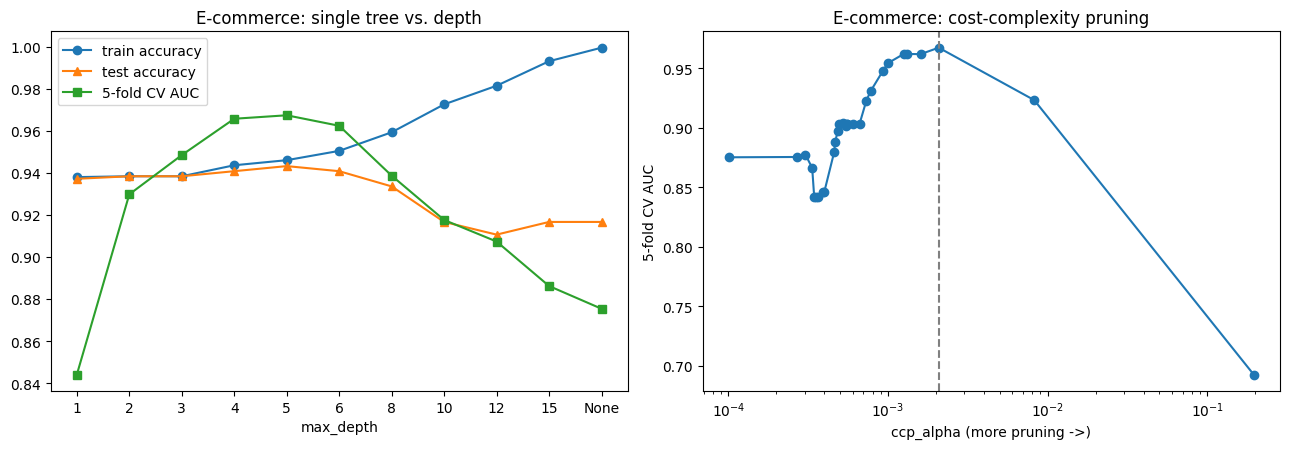

In [2]:
df = pd.read_csv("ecommerce_data.csv")
numeric_cols = ["Sales", "Quantity", "Discount"]
categorical_cols = ["Segment", "Region", "Ship Mode", "Category", "Sub-Category"]
X = pd.get_dummies(df[numeric_cols + categorical_cols], columns=categorical_cols, drop_first=True).astype(float)
y = (df["Profit"] > 0).astype(int).values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(X.shape, f"profitable share {y.mean():.1%}; majority-class baseline accuracy {max(y.mean(), 1-y.mean()):.3f}")

depths = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, None]
tr_acc, cv_auc, te_acc = [], [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    tr_acc.append(t.score(X_train, y_train)); te_acc.append(t.score(X_test, y_test))
    cv_auc.append(cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=42), X_train, y_train, cv=cv5, scoring="roc_auc").mean())
depth_table = pd.DataFrame({"max_depth": [str(d) for d in depths], "train_acc": tr_acc, "cv_AUC": cv_auc, "test_acc": te_acc})
print(depth_table.round(3).to_string(index=False))

path = DecisionTreeClassifier(random_state=42).cost_complexity_pruning_path(X_train, y_train)
alphas = np.unique(np.round(path.ccp_alphas, 6))
alphas = alphas[(alphas > 0)][::max(1, len(alphas) // 25)]
ccp_cv = [cross_val_score(DecisionTreeClassifier(ccp_alpha=a, random_state=42), X_train, y_train, cv=cv5, scoring="roc_auc").mean() for a in alphas]
best_alpha = alphas[int(np.argmax(ccp_cv))]
print(f"best ccp_alpha by CV AUC: {best_alpha:.5f} (CV AUC {max(ccp_cv):.3f})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
x_pos = range(len(depths))
axes[0].plot(x_pos, tr_acc, "o-", label="train accuracy"); axes[0].plot(x_pos, te_acc, "^-", label="test accuracy")
axes[0].plot(x_pos, cv_auc, "s-", label="5-fold CV AUC")
axes[0].set_xticks(list(x_pos)); axes[0].set_xticklabels([str(d) for d in depths])
axes[0].set_xlabel("max_depth"); axes[0].set_title("E-commerce: single tree vs. depth"); axes[0].legend()
axes[1].semilogx(alphas, ccp_cv, "o-"); axes[1].axvline(best_alpha, color="gray", ls="--")
axes[1].set_xlabel("ccp_alpha (more pruning ->)"); axes[1].set_ylabel("5-fold CV AUC"); axes[1].set_title("E-commerce: cost-complexity pruning")
plt.tight_layout(); plt.show()

### A2. What does a shallow tree actually say?

A depth-3 tree is small enough to read.

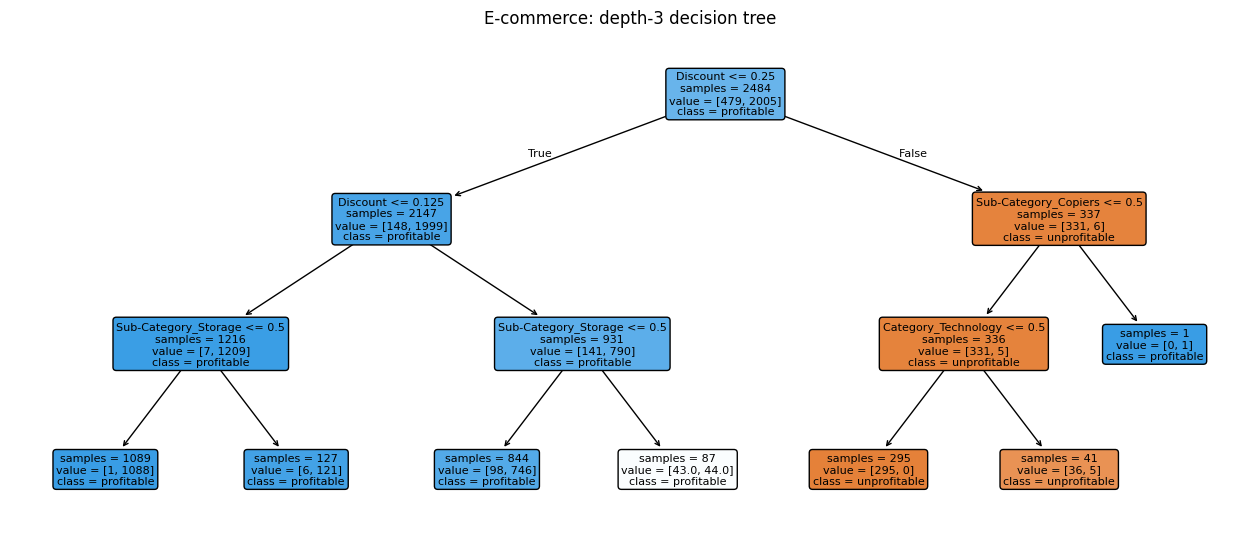

In [3]:
shallow = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)
plt.figure(figsize=(16, 6.5))
plot_tree(shallow, feature_names=X.columns, class_names=["unprofitable", "profitable"], filled=True, rounded=True, fontsize=8, impurity=False)
plt.title("E-commerce: depth-3 decision tree"); plt.show()

### A3. Random forest: tuning and comparison with Weeks 4-5

A random forest averages many trees, each trained on a bootstrap sample and restricted to a random subset of features at every split, which decorrelates the trees and cuts variance. I tune `n_estimators`, `max_depth`, `min_samples_leaf`, and `max_features` with randomized search (5-fold CV, scored on ROC AUC), then report the out-of-bag (OOB) score as a second, free estimate of generalization. For a like-for-like table I refit the Week 4 logistic regression and the Week 5 tuned RBF SVM on the same split.

In [4]:
search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    {"n_estimators": [100, 200, 300], "max_depth": [3, 5, 8, 12, None],
     "min_samples_leaf": [1, 2, 5, 10], "max_features": ["sqrt", 0.3, 0.6, 1.0]},
    n_iter=15, scoring="roc_auc", cv=cv5, random_state=42, n_jobs=-1).fit(X_train, y_train)
print("best params:", search.best_params_, f"CV AUC {search.best_score_:.4f}")

rf = RandomForestClassifier(**search.best_params_, oob_score=True, random_state=42, n_jobs=-1).fit(X_train, y_train)
print(f"OOB accuracy: {rf.oob_score_:.3f}")

# comparison models from earlier weeks, same split
sc = StandardScaler().fit(X_train); Xs_tr, Xs_te = sc.transform(X_train), sc.transform(X_test)
logit = LogisticRegressionCV(Cs=np.logspace(-2, 3, 50), cv=5, scoring="roc_auc", max_iter=5000).fit(Xs_tr, y_train)
svm = SVC(kernel="rbf", C=1000, gamma=0.001).fit(Xs_tr, y_train)
best_tree = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_train, y_train)

rows = [evaluate("Logistic regression (Week 4)", y_test, logit.decision_function(Xs_te), logit.predict(Xs_te), 0),
        evaluate("RBF SVM (Week 5)", y_test, svm.decision_function(Xs_te), svm.predict(Xs_te), 0),
        evaluate("Single tree, depth 5", y_test, best_tree.predict_proba(X_test)[:, 1], best_tree.predict(X_test), 0),
        evaluate("Random forest (tuned)", y_test, rf.predict_proba(X_test)[:, 1], rf.predict(X_test), 0)]
ecom_table = pd.DataFrame(rows).set_index("model")
ecom_table.round(3)

best params: {'n_estimators': 300, 'min_samples_leaf': 10, 'max_features': 1.0, 'max_depth': 8} CV AUC 0.9785


OOB accuracy: 0.937


,accuracy,roc_auc,f1_minority,precision_minority,recall_minority
model,,,,,
Logistic regression (Week 4),0.925,0.976,0.804,0.814,0.794
RBF SVM (Week 5),0.935,0.965,0.825,0.858,0.794
"Single tree, depth 5",0.943,0.969,0.834,0.959,0.738
Random forest (tuned),0.944,0.980,0.844,0.925,0.775


### A4. Which features matter? Impurity importance vs. permutation importance

Random forests report an *impurity-based* feature importance for free, but it is computed on training data and is known to favor continuous or high-cardinality features (they offer more places to split). *Permutation importance* instead measures how much the held-out test AUC drops when a feature's values are shuffled. If the two disagree, I trust the permutation version.

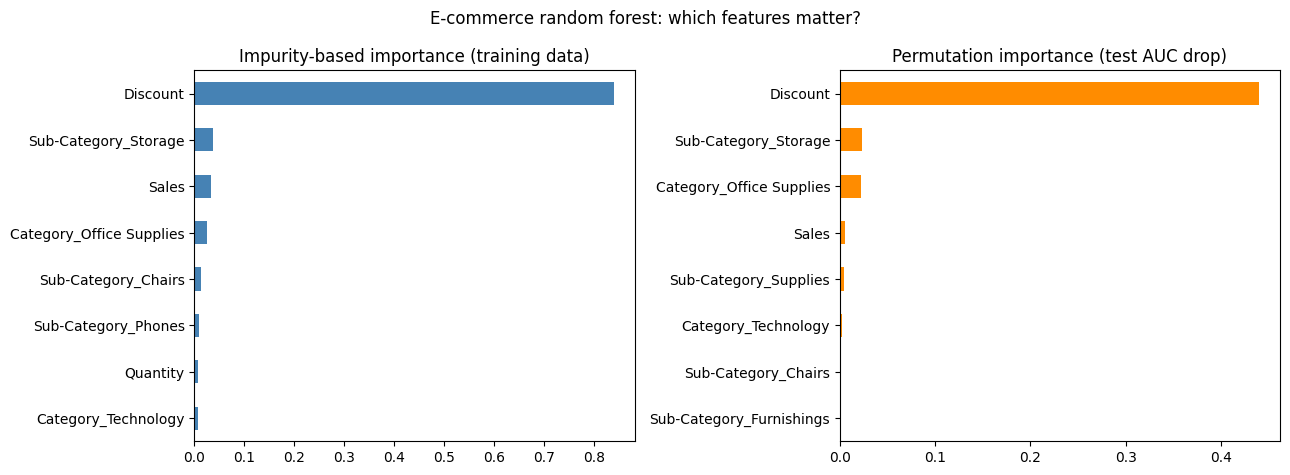

                          impurity  permutation
Discount                     0.839        0.440
Sub-Category_Storage         0.038        0.023
Sales                        0.033        0.006
Category_Office Supplies     0.026        0.022
Sub-Category_Chairs          0.013        0.001
Sub-Category_Phones          0.010        0.000


In [5]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
perm = permutation_importance(rf, X_test, y_test, n_repeats=10, scoring="roc_auc", random_state=42, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
imp.head(8)[::-1].plot.barh(ax=axes[0], color="steelblue"); axes[0].set_title("Impurity-based importance (training data)")
perm_s.head(8)[::-1].plot.barh(ax=axes[1], color="darkorange"); axes[1].set_title("Permutation importance (test AUC drop)")
plt.suptitle("E-commerce random forest: which features matter?"); plt.tight_layout(); plt.show()
print(pd.DataFrame({"impurity": imp.head(6), "permutation": perm_s.reindex(imp.head(6).index)}).round(3))

### A5. Does a forest help predict the *amount* of profit? (link back to Weeks 1-3)

Weeks 2-3 found that linear models of the dollar profit topped out around R² of 0.28. Trees capture nonlinearities and interactions (what Week 1's polynomial and interaction terms did by hand), so I check whether a random forest breaks through that ceiling. Same split as Weeks 2-3.

In [6]:
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(X, df["Profit"].values, test_size=0.25, random_state=42)
ols = LinearRegression().fit(Xr_tr, yr_tr)
rfr = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1).fit(Xr_tr, yr_tr)
reg_table = pd.DataFrame({"test_R2": [r2_score(yr_te, ols.predict(Xr_te)), r2_score(yr_te, rfr.predict(Xr_te))],
                          "test_RMSE": [mean_squared_error(yr_te, ols.predict(Xr_te))**0.5, mean_squared_error(yr_te, rfr.predict(Xr_te))**0.5]},
                         index=["OLS (Weeks 2-3)", "Random forest regressor"])
print(reg_table.round(3))
print("\nProfit distribution: min %.0f, median %.1f, max %.0f; top 1%% of orders hold %.0f%% of total absolute profit"
      % (df.Profit.min(), df.Profit.median(), df.Profit.max(),
         100 * df.Profit.abs().nlargest(int(len(df)*0.01)).sum() / df.Profit.abs().sum()))

                         test_R2  test_RMSE
OLS (Weeks 2-3)            0.281    272.322
Random forest regressor    0.257    276.767

Profit distribution: min -3840, median 8.3, max 6720; top 1% of orders hold 29% of total absolute profit


## Part B - Amazon reviews: is this review negative?

Same label and split as Week 5 (ratings 1-2 negative, 4-5 positive, 3-star dropped; rating is never a feature). I compare (1) a forest on **metadata** features such as review length, which is the kind of model my proposal used, and (2) a forest on **TF-IDF text** features. Class imbalance (about 1:7) is handled with `class_weight="balanced_subsample"`, which reweights each bootstrap sample.

Hyperparameter tuning in this notebook is concentrated on the e-commerce and Instacart forests; the Amazon forests use sensible defaults on purpose, because the point here is the comparison between feature sets and with Week 5's SVM.

In [7]:
a = pd.read_csv("amazon_review_data.csv")
a = a[a["rating"] != 3].copy()
a["negative"] = (a["rating"] <= 2).astype(int)
a["title"] = a["title"].fillna(""); a["text"] = a["text"].fillna("")
a["full_text"] = a["title"] + ". " + a["text"]
a["review_length"] = a["text"].str.len(); a["word_count"] = a["text"].str.split().str.len()
a["title_length"] = a["title"].str.len(); a["exclaims"] = a["text"].str.count("!")
a["caps_ratio"] = a["text"].apply(lambda s: sum(ch.isupper() for ch in s) / max(len(s), 1))
a["verified"] = a["verified_purchase"].astype(int)
a["category_code"] = a["category_name"].astype("category").cat.codes
meta_cols = ["review_length", "word_count", "title_length", "exclaims", "caps_ratio", "verified", "helpful_vote", "category_code"]

a_train, a_test = train_test_split(a, test_size=0.25, random_state=42, stratify=a["negative"])
ya_tr, ya_te = a_train["negative"].values, a_test["negative"].values
print(a.shape, f"{a['negative'].mean():.1%} negative")

# single tree overfitting on metadata
rows = []
for d in [2, 4, 8, 12, None]:
    t = DecisionTreeClassifier(max_depth=d, class_weight="balanced", random_state=42).fit(a_train[meta_cols], ya_tr)
    rows.append({"max_depth": str(d), "train_F1": f1_score(ya_tr, t.predict(a_train[meta_cols])), "test_F1": f1_score(ya_te, t.predict(a_test[meta_cols]))})
print(pd.DataFrame(rows).round(3).to_string(index=False))

(9373, 20) 12.4% negative
max_depth  train_F1  test_F1
        2     0.249    0.252
        4     0.276    0.269
        8     0.376    0.254
       12     0.497    0.237
     None     0.999    0.190


In [8]:
amazon_rows = []
for cw, label in [(None, "RF on metadata (no class weights)"), ("balanced_subsample", "RF on metadata (balanced)")]:
    m = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight=cw, random_state=42, n_jobs=-1).fit(a_train[meta_cols], ya_tr)
    amazon_rows.append(evaluate(label, ya_te, m.predict_proba(a_test[meta_cols])[:, 1], m.predict(a_test[meta_cols]), 1))
rf_meta = m

vec = TfidfVectorizer(stop_words="english", min_df=3, max_features=3000, sublinear_tf=True).fit(a_train["full_text"])
T_tr, T_te = vec.transform(a_train["full_text"]), vec.transform(a_test["full_text"])
rf_text = RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", random_state=42, n_jobs=-1).fit(T_tr, ya_tr)
amazon_rows.append(evaluate("RF on TF-IDF text", ya_te, rf_text.predict_proba(T_te)[:, 1], rf_text.predict(T_te), 1))

# Week 5 SVM for comparison (same split, same TF-IDF recipe)
svm_pipe = Pipeline([("tfidf", TfidfVectorizer(stop_words="english", min_df=3, max_features=8000, ngram_range=(1, 2), sublinear_tf=True)),
                     ("svm", LinearSVC(C=0.3, class_weight="balanced", dual=True, max_iter=50000))]).fit(a_train["full_text"], ya_tr)
amazon_rows.append(evaluate("TF-IDF + linear SVM (Week 5)", ya_te, svm_pipe.decision_function(a_test["full_text"]), svm_pipe.predict(a_test["full_text"]), 1))
amazon_table = pd.DataFrame(amazon_rows).set_index("model")
amazon_table.round(3)

,accuracy,roc_auc,f1_minority,precision_minority,recall_minority
model,,,,,
RF on metadata (no class weights),0.876,0.698,0.033,0.500,0.017
RF on metadata (balanced),0.868,0.699,0.144,0.371,0.089
RF on TF-IDF text,0.921,0.945,0.580,0.853,0.440
TF-IDF + linear SVM (Week 5),0.936,0.957,0.752,0.724,0.784


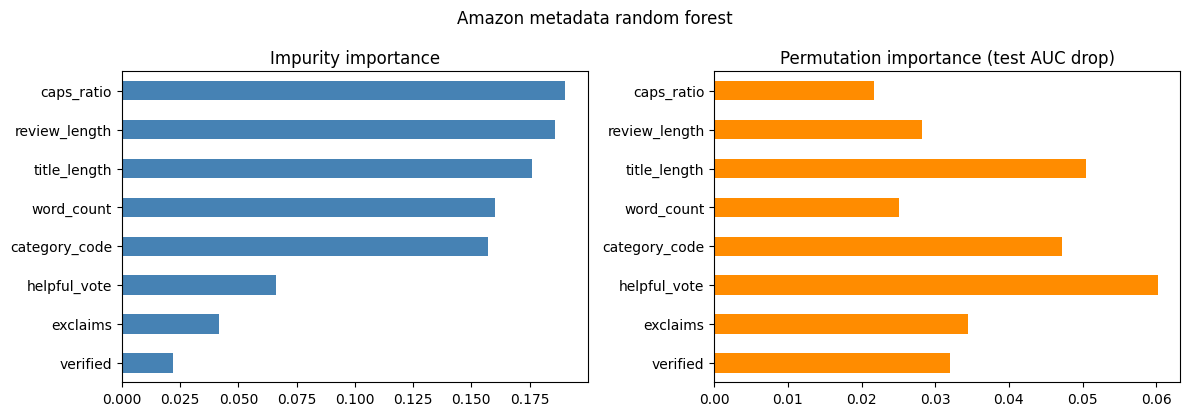

[[2009   44]
 [ 265   26]]


In [9]:
perm_a = permutation_importance(rf_meta, a_test[meta_cols], ya_te, n_repeats=10, scoring="roc_auc", random_state=42, n_jobs=-1)
imp_a = pd.Series(rf_meta.feature_importances_, index=meta_cols).sort_values()
perm_as = pd.Series(perm_a.importances_mean, index=meta_cols).reindex(imp_a.index)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
imp_a.plot.barh(ax=axes[0], color="steelblue"); axes[0].set_title("Impurity importance")
perm_as.plot.barh(ax=axes[1], color="darkorange"); axes[1].set_title("Permutation importance (test AUC drop)")
plt.suptitle("Amazon metadata random forest"); plt.tight_layout(); plt.show()
print(confusion_matrix(ya_te, rf_meta.predict(a_test[meta_cols])))

## Part C - Instacart: will this item be a reorder?

Features, all known when the order is placed: days since the customer's previous order, hour of day, day of week, the item's position in the cart (`add_to_cart_order`), the customer's `order_number`, and ordinal codes for aisle and department. Two points about the data:

- `days_since_prior_order` is missing exactly on a customer's *first* order, and by definition nothing in a first order can be a reorder. I fill it with -1 so the trees can see "first order" directly.
- `order_number` is not a leak (it is known at order time) but it is a very strong signal, so I also report a version without it.
- Aisle and department are label-encoded, which is fine for trees (no scaling or one-hot needed) though the integer order is arbitrary.

share reordered when days_since_prior_order is missing: 0.0 | otherwise: 0.63
(11250, 7) majority-class baseline accuracy 0.592


max_depth  train_acc  cv_AUC  test_acc
        2      0.701   0.716     0.695
        4      0.715   0.735     0.698
        6      0.728   0.746     0.707
        8      0.745   0.736     0.705
       10      0.777   0.714     0.695
       15      0.899   0.646     0.664
     None      1.000   0.624     0.647


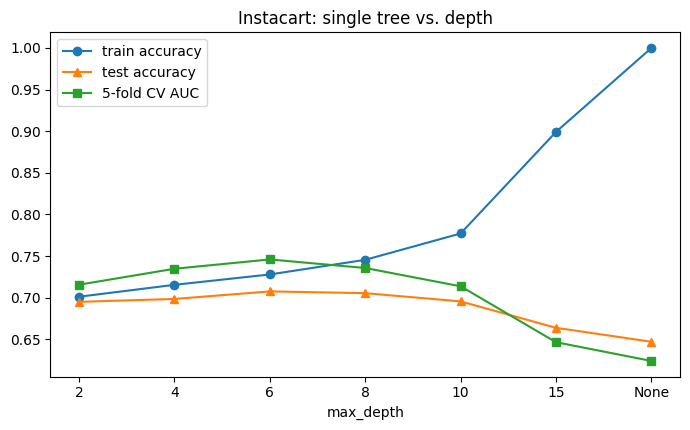

In [10]:
ins = pd.read_csv("insta_df_sample.csv")
print("share reordered when days_since_prior_order is missing:", ins.loc[ins["days_since_prior_order"].isna(), "reordered"].mean(),
      "| otherwise:", round(ins.loc[ins["days_since_prior_order"].notna(), "reordered"].mean(), 3))
ins["days_since_prior"] = ins["days_since_prior_order"].fillna(-1)
ins["aisle_code"] = ins["aisle"].astype("category").cat.codes
ins["dept_code"] = ins["department"].astype("category").cat.codes
i_feats = ["days_since_prior", "order_hour_of_day", "add_to_cart_order", "order_dow", "order_number", "aisle_code", "dept_code"]
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(ins[i_feats], ins["reordered"].values, test_size=0.25, random_state=42, stratify=ins["reordered"])
print(Xi_tr.shape, f"majority-class baseline accuracy {max(ins['reordered'].mean(), 1-ins['reordered'].mean()):.3f}")

rows, i_depths = [], [2, 4, 6, 8, 10, 15, None]
for d in i_depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(Xi_tr, yi_tr)
    cvs = cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=42), Xi_tr, yi_tr, cv=cv5, scoring="roc_auc").mean()
    rows.append({"max_depth": str(d), "train_acc": t.score(Xi_tr, yi_tr), "cv_AUC": cvs, "test_acc": t.score(Xi_te, yi_te)})
i_depth = pd.DataFrame(rows); print(i_depth.round(3).to_string(index=False))

plt.figure(figsize=(7, 4.4))
xp = range(len(i_depths))
plt.plot(xp, i_depth["train_acc"], "o-", label="train accuracy"); plt.plot(xp, i_depth["test_acc"], "^-", label="test accuracy")
plt.plot(xp, i_depth["cv_AUC"], "s-", label="5-fold CV AUC")
plt.xticks(list(xp), [str(d) for d in i_depths]); plt.xlabel("max_depth"); plt.title("Instacart: single tree vs. depth"); plt.legend(); plt.tight_layout(); plt.show()

In [11]:
i_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    {"n_estimators": [100, 200], "max_depth": [6, 10, 15, None], "min_samples_leaf": [5, 10, 20, 40], "max_features": ["sqrt", 0.5, 1.0]},
    n_iter=10, scoring="roc_auc", cv=cv3, random_state=42, n_jobs=-1).fit(Xi_tr, yi_tr)
print("best params:", i_search.best_params_, f"CV AUC {i_search.best_score_:.4f}")
rf_i = RandomForestClassifier(**i_search.best_params_, oob_score=True, random_state=42, n_jobs=-1).fit(Xi_tr, yi_tr)
print(f"OOB accuracy: {rf_i.oob_score_:.3f}")

no_on = [f for f in i_feats if f != "order_number"]
rf_i2 = RandomForestClassifier(**i_search.best_params_, random_state=42, n_jobs=-1).fit(Xi_tr[no_on], yi_tr)
num_cols = ["days_since_prior", "order_hour_of_day", "add_to_cart_order", "order_dow", "order_number"]
si = StandardScaler().fit(Xi_tr[num_cols])
lr_i = LogisticRegressionCV(Cs=np.logspace(-2, 2, 20), cv=5, scoring="roc_auc", max_iter=5000).fit(si.transform(Xi_tr[num_cols]), yi_tr)

rows = [evaluate("Logistic regression (numeric features)", yi_te, lr_i.decision_function(si.transform(Xi_te[num_cols])), lr_i.predict(si.transform(Xi_te[num_cols])), 0),
        evaluate("Random forest (tuned)", yi_te, rf_i.predict_proba(Xi_te)[:, 1], rf_i.predict(Xi_te), 0),
        evaluate("Random forest without order_number", yi_te, rf_i2.predict_proba(Xi_te[no_on])[:, 1], rf_i2.predict(Xi_te[no_on]), 0)]
insta_table = pd.DataFrame(rows).set_index("model"); insta_table.round(3)

best params: {'n_estimators': 200, 'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': None} CV AUC 0.7791


OOB accuracy: 0.725


,accuracy,roc_auc,f1_minority,precision_minority,recall_minority
model,,,,,
Logistic regression (numeric features),0.693,0.732,0.581,0.655,0.522
Random forest (tuned),0.724,0.783,0.601,0.731,0.510
Random forest without order_number,0.697,0.728,0.518,0.738,0.399


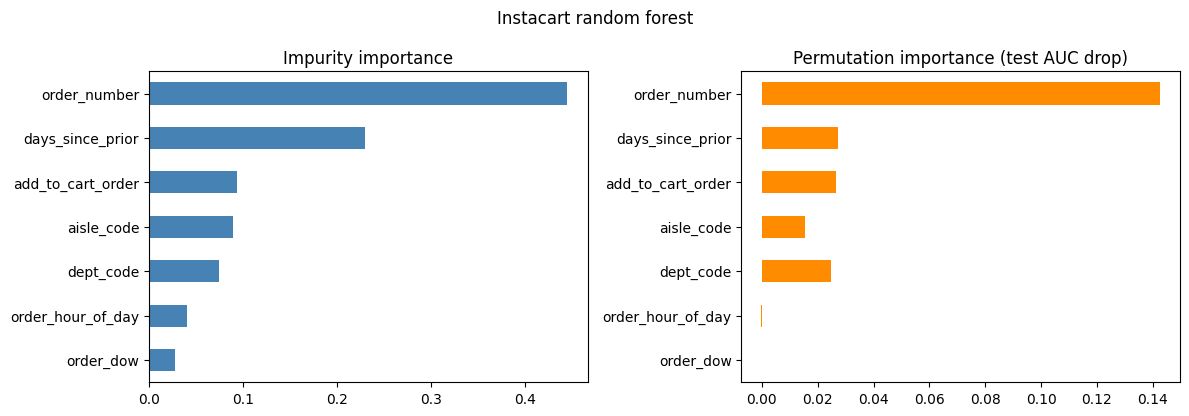

                   impurity  permutation
order_number          0.444        0.143
days_since_prior      0.230        0.027
add_to_cart_order     0.094        0.026
dept_code             0.074        0.025
aisle_code            0.089        0.016
order_dow             0.028        0.000
order_hour_of_day     0.041       -0.000


In [12]:
imp_i = pd.Series(rf_i.feature_importances_, index=i_feats).sort_values()
perm_i = permutation_importance(rf_i, Xi_te, yi_te, n_repeats=10, scoring="roc_auc", random_state=42, n_jobs=-1)
perm_is = pd.Series(perm_i.importances_mean, index=i_feats).reindex(imp_i.index)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
imp_i.plot.barh(ax=axes[0], color="steelblue"); axes[0].set_title("Impurity importance")
perm_is.plot.barh(ax=axes[1], color="darkorange"); axes[1].set_title("Permutation importance (test AUC drop)")
plt.suptitle("Instacart random forest"); plt.tight_layout(); plt.show()
print(pd.DataFrame({"impurity": imp_i, "permutation": perm_is}).sort_values("permutation", ascending=False).round(3))

### C1. Revisiting the Instacart importance ranking from my capstone proposal

My proposal reported an Instacart random forest in which `order_hour_of_day` and `order_dow` ranked high (importance of about 0.22 and 0.13), which I read as "shopping cadence beats product category." That model had no `order_number` and used default settings (fully grown trees). I rebuild that setup here (default forest, without `order_number`) and compare impurity importance with permutation importance.

In [13]:
base_feats = [f for f in i_feats if f != "order_number"]
rows = {}
for name, kw in [("default forest", {}), ("regularized forest (min_samples_leaf=20)", {"min_samples_leaf": 20})]:
    m = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1, **kw).fit(Xi_tr[base_feats], yi_tr)
    p = permutation_importance(m, Xi_te[base_feats], yi_te, n_repeats=5, scoring="roc_auc", random_state=42, n_jobs=-1)
    rows[name] = (m.score(Xi_te[base_feats], yi_te), pd.DataFrame({"impurity": m.feature_importances_, "permutation": p.importances_mean}, index=base_feats))
for name, (acc, tab) in rows.items():
    print(f"{name}: test accuracy {acc:.3f}")
    print(tab.sort_values("impurity", ascending=False).round(3)); print()

default forest: test accuracy 0.659
                   impurity  permutation
days_since_prior      0.288        0.107
order_hour_of_day     0.187       -0.000
add_to_cart_order     0.171        0.030
aisle_code            0.150        0.020
order_dow             0.120       -0.002
dept_code             0.084        0.041

regularized forest (min_samples_leaf=20): test accuracy 0.697
                   impurity  permutation
days_since_prior      0.489        0.111
aisle_code            0.139        0.021
add_to_cart_order     0.132        0.039
dept_code             0.118        0.046
order_hour_of_day     0.071        0.002
order_dow             0.051        0.001



## Summary tables

In [14]:
print("E-commerce - profitable vs. unprofitable orders (minority = unprofitable)"); display(ecom_table.round(3))
print("\nAmazon - negative reviews (minority = negative)"); display(amazon_table.round(3))
print("\nInstacart - reordered items (class 0 = not reordered)"); display(insta_table.round(3))

E-commerce - profitable vs. unprofitable orders (minority = unprofitable)


,accuracy,roc_auc,f1_minority,precision_minority,recall_minority
model,,,,,
Logistic regression (Week 4),0.925,0.976,0.804,0.814,0.794
RBF SVM (Week 5),0.935,0.965,0.825,0.858,0.794
"Single tree, depth 5",0.943,0.969,0.834,0.959,0.738
Random forest (tuned),0.944,0.980,0.844,0.925,0.775



Amazon - negative reviews (minority = negative)


,accuracy,roc_auc,f1_minority,precision_minority,recall_minority
model,,,,,
RF on metadata (no class weights),0.876,0.698,0.033,0.500,0.017
RF on metadata (balanced),0.868,0.699,0.144,0.371,0.089
RF on TF-IDF text,0.921,0.945,0.580,0.853,0.440
TF-IDF + linear SVM (Week 5),0.936,0.957,0.752,0.724,0.784



Instacart - reordered items (class 0 = not reordered)


,accuracy,roc_auc,f1_minority,precision_minority,recall_minority
model,,,,,
Logistic regression (numeric features),0.693,0.732,0.581,0.655,0.522
Random forest (tuned),0.724,0.783,0.601,0.731,0.510
Random forest without order_number,0.697,0.728,0.518,0.738,0.399


## Conclusions

**Overfitting, and what fixed it**

- A single unrestricted tree memorizes its training data on every dataset. E-commerce: training accuracy 1.000 but test accuracy 0.917 and CV AUC 0.875, versus CV AUC 0.967 for a depth-5 tree (and the same 0.967 from cost-complexity pruning at `ccp_alpha` of about 0.002, so depth limits and pruning land in the same place). Instacart: an unrestricted tree has training accuracy 1.000 against test accuracy 0.647, while a depth-6 tree reaches 0.707. Amazon metadata: training F1 0.999 against test F1 0.19 for the unrestricted tree.
- The random forest reduces that variance by averaging. The tuned e-commerce forest (depth 8, `min_samples_leaf` 10, 300 trees) has an OOB accuracy of 0.937 that agrees with its test accuracy of 0.944, and the tuned Instacart forest has an OOB accuracy of 0.725 against a test accuracy of 0.724, so I see no sign that either forest is overfitting. The OOB estimate is useful here because it comes free from the bootstrap and does not need a second validation split.

**E-commerce: what the forest learned**

- The depth-3 tree reads like a business rule: orders with a discount above 25% are 98% unprofitable (331 of 337 in the training split), and below that the model separates only the remaining losses by sub-category (for example Storage). Discount dominates the forest: 0.84 impurity importance and a 0.44 drop in test AUC when it is shuffled, compared with about 0.03 and 0.006 for `Sales`.
- That differs from my capstone proposal's e-commerce forest, where `Sales` led (0.47) and `Discount` was second (0.20). Those models had different targets (the proposal predicted high vs. low profit; here the target is profit vs. loss), which is the likely reason: `Sales` mostly sets how *large* a profit is, while `Discount` mostly decides whether an order *loses money*.
- The tuned forest was the best model on every metric (AUC 0.980, F1 on unprofitable orders 0.844) against logistic regression (0.976, 0.804), the RBF SVM (0.965, 0.825), and a single depth-5 tree (0.969, 0.834). The margins are small, though: the single pruned tree reaches the same 0.943 accuracy, which tells me the signal is simple and the forest mainly adds stability.
- Surprise: for the dollar amount of profit, the random forest regressor (R² = 0.257) did *not* beat plain OLS (0.281), even though trees capture nonlinearities and interactions automatically. The top 1% of orders hold 29% of all absolute profit, so a few extreme orders dominate the error, and shipping costs and returns are not in the data. That fits the Week 2-3 conclusion that the ceiling is the information in the features, not the model family.

**Amazon: trees on text**

- A forest on metadata alone (length, helpful votes, verified purchase, and so on) found almost no negative reviews: F1 of 0.03 without class weights and 0.14 with them, and the balanced model catches only 26 of the 291 negative reviews in the test set (AUC about 0.70). This reproduces the weakness I saw in my proposal's Amazon model (very low precision and recall on the negative class), and the metadata SVM from Week 5 failed in the same way.
- A forest on TF-IDF text does much better (AUC 0.945, F1 0.58, precision 0.85 but recall only 0.44 at the default 0.5 threshold), yet the Week 5 linear SVM is still clearly better on the metric that matters here (F1 0.752, recall 0.78). My explanation, which I have not tested further, is that each individual word is rare, so trees need many splits to accumulate evidence, whereas a linear model simply adds up the evidence from many words. Lowering the forest's decision threshold would raise recall at some cost in precision; I did not tune that.

**Instacart: correcting my proposal's importance ranking**

- Items in a customer's first order can never be reorders (0% reordered when `days_since_prior_order` is missing, 63% otherwise), and `order_number` is the strongest predictor: removing it drops the forest's AUC from 0.783 to 0.728, which is about what a logistic regression on the numeric features achieves (0.732).
- The default forest on my proposal's feature set (C1) reproduces the proposal's ranking (days since prior order 0.29, hour of day 0.19, cart position 0.17, aisle 0.15, day of week 0.12, department 0.08; test accuracy 0.659 against 0.64 reported there). But **permutation importance says hour of day and day of week contribute nothing** (changes in AUC of about 0.000 and -0.002), while days since prior order (0.107), department (0.041), and cart position (0.030) do carry signal. Impurity importance is computed on the training data and rewards features with many distinct values that fully grown trees can split on, noise included. The corrected finding is narrower than what I wrote in the proposal: reorder behavior depends on shopping cadence (how long since the last order) and customer tenure (`order_number`), not on the time of day or day of the week.

**Expected vs. unexpected**

- Expected: unpruned trees overfit; forests generalize better; trees need no scaling; text needs text features.
- Unexpected: (1) the forest barely beat logistic regression and a single pruned tree on e-commerce; (2) it did not beat OLS for dollar profit; (3) two of the features I had interpreted as important in my proposal (order hour and day of week) turned out not to matter once importance was measured on held-out data.